# Party gap baseline

Roadmap step 1. This notebook answers three questions before any clustering starts:

1. Can we rebuild Voteview's party gap from the processed data?
2. Do measures built from raw votes tell the same story?
3. Which measures are fit for studying convergence?

The unit is one Congress in one chamber, for each Congress with at least 10 Democrats and 10 Republicans (1857 onward). Territorial delegates are excluded. The 119th Congress (2025 onward) is still in progress: data runs to 2026-09-30, so it is plotted but left out of correlations, comparisons and record claims.

**Data status:** the processed data is internally consistent with Voteview. Individual votes are externally confirmed only for a sample: 40 House roll calls from 2003 on, with no disagreements. That result still allows some roll calls to contain errors. Senate votes and earlier House votes are not externally confirmed.

This notebook describes voting behaviour on votes that reached the floor. Leaders' agenda control affects which votes those are, and comparing 1900 with today assumes a stable scale and agenda. Neither assumption is tested here.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.sparse.linalg import svds

sys.path.append(str(Path.cwd().parents[1] / "data_loading"))
from voteview import load_members, load_rollcalls, load_votes, pivot_votes

COLORS = {"D": "#2a78d6", "R": "#c93b3b"}
NEUTRAL = "#52514e"
MODERN_CONGRESS = 79
INCOMPLETE_CONGRESS = 119
MIN_PARTY_MEMBERS = 10
CHAMBERS = ["House", "Senate"]
rng = np.random.default_rng(0)

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ad",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "text.color": "#0b0b0b", "xtick.color": NEUTRAL, "ytick.color": NEUTRAL,
    "legend.frameon": False,
})


def first_year(congress):
    return 1789 + 2 * (congress - 1)


all_members = load_members()
members = all_members[~all_members["is_delegate"]]
rollcalls = load_rollcalls()
rollcall_keys = ["congress", "chamber", "rollnumber"]
all_votes = load_votes().merge(members[["congress", "chamber", "icpsr", "party"]], on=["congress", "chamber", "icpsr"])
positions = all_votes[(all_votes["vote"] != 0) & all_votes["party"].isin(["D", "R"])]
party_rolls = positions.assign(yea=positions["vote"].eq(1)).groupby(rollcall_keys + ["party"])["yea"].agg(["mean", "count"]).unstack().dropna()
shares = pd.DataFrame({
    "D": party_rolls[("mean", "D")], "R": party_rolls[("mean", "R")],
    "n_D": party_rolls[("count", "D")], "n_R": party_rolls[("count", "R")],
}).join(rollcalls.set_index(rollcall_keys)[["is_lopsided", "minority_share"]])
contested = rollcalls.loc[~rollcalls["is_lopsided"], rollcall_keys]
votes = all_votes.merge(contested, on=rollcall_keys)
print(f"{len(members):,} member records, {len(contested):,} of {len(rollcalls):,} roll calls kept, {len(votes):,} votes")


50,893 member records, 101,694 of 113,568 roll calls kept, 22,712,861 votes


Vote measures use **contested** roll calls by default, meaning the smaller side has at least 2.5% of Yea and Nay positions, including paired and announced positions. Absences never count as Nay. Cutoffs of 0% and 10% are tested below.

In [2]:
def score_gap(group, column):
    scores = group.groupby("party")[column].mean()
    return scores["R"] - scores["D"]


def overlap_share(group, column):
    two_party = group[group["party"].isin(["D", "R"])].dropna(subset=[column])
    right_of_democrats = two_party[two_party["party"] == "D"][column].max()
    left_of_republicans = two_party[two_party["party"] == "R"][column].min()
    return two_party[column].between(left_of_republicans, right_of_democrats).mean()


def cross_agreement(frame):
    return frame["D"] * frame["R"] + (1 - frame["D"]) * (1 - frame["R"])


def same_party_agreement(share, voters):
    alike = share * voters * (share * voters - 1) + (1 - share) * voters * ((1 - share) * voters - 1)
    return (alike / (voters * (voters - 1))).where(voters > 1)


def vote_measures(frame):
    dem, rep = frame["D"], frame["R"]
    return pd.Series({
        "rollcalls": len(frame),
        "party_opposed": ((dem - 0.5) * (rep - 0.5) < 0).mean(),
        "rice_gap": (dem - rep).abs().mean(),
        "cross_agreement": cross_agreement(frame).mean(),
        "dem_agreement": same_party_agreement(dem, frame["n_D"]).mean(),
        "rep_agreement": same_party_agreement(rep, frame["n_R"]).mean(),
    })


def pc1_measures(group, scores):
    matrix = pivot_votes(group)
    matrix = matrix[matrix.notna().sum(axis=1) >= 20]
    matrix = matrix.loc[:, matrix.notna().sum() >= 5]
    values = matrix.to_numpy(dtype="float64")
    values = values - np.nanmean(values, axis=0)
    values = np.nan_to_num(values)
    values = values - values.mean(axis=1, keepdims=True)
    left, singular, _ = svds(values, k=2)
    order = np.argsort(singular)[::-1]
    pc1 = pd.Series(left[:, order[0]] * singular[order[0]], index=matrix.index)
    parties = group.drop_duplicates("icpsr").set_index("icpsr")["party"].reindex(pc1.index)
    dem, rep = pc1[parties == "D"], pc1[parties == "R"]
    if rep.mean() < dem.mean():
        dem, rep, pc1 = -dem, -rep, -pc1
    pooled = np.sqrt((dem.var() + rep.var()) / 2)
    total = np.sum(values**2)
    return pd.Series({
        "pc1_separation": (rep.mean() - dem.mean()) / pooled,
        "pc1_variance_share": singular[order[0]] ** 2 / total,
        "pc2_variance_share": singular[order[1]] ** 2 / total,
        "pc1_dw_corr": pc1.corr(scores.reindex(pc1.index)),
    })


contested_shares = shares[~shares["is_lopsided"]]
votes_by_chamber = votes.groupby(["congress", "chamber"])
rows = []
for (congress, chamber), group in members.groupby(["congress", "chamber"]):
    counts = group["party"].value_counts()
    if counts.get("D", 0) < MIN_PARTY_MEMBERS or counts.get("R", 0) < MIN_PARTY_MEMBERS:
        continue
    chamber_votes = votes_by_chamber.get_group((congress, chamber))
    rows.append({
        "congress": congress, "chamber": chamber, "year": first_year(congress),
        "dw_gap": score_gap(group, "nominate_dim1"),
        "np_gap": score_gap(group, "nokken_poole_dim1"),
        "dw_overlap": overlap_share(group, "nominate_dim1"),
        "np_overlap": overlap_share(group, "nokken_poole_dim1"),
        **vote_measures(contested_shares.loc[(congress, chamber)]),
        **pc1_measures(chamber_votes, group.set_index("icpsr")["nominate_dim1"]),
    })
series = pd.DataFrame(rows)
complete = series[series["congress"] < INCOMPLETE_CONGRESS]
print(series["congress"].min(), series["congress"].max(), series.groupby("chamber").size().to_dict())
with pd.option_context("display.width", 170, "display.max_columns", 30, "display.precision", 3):
    display(series[series["congress"].isin([40, 60, 80, 90, 95, 100, 105, 110, 115, 118, 119])].set_index(["chamber", "congress"]).sort_index())


35 119 {'House': 85, 'Senate': 85}


year  dw_gap  np_gap  dw_overlap  np_overlap  rollcalls  party_opposed  rice_gap  cross_agreement  dem_agreement  rep_agreement  pc1_separation  \
chamber congress                                                                                                                                                    
House   40        1867   0.677   0.696       0.000       0.000      707.0          0.745     0.596            0.316          0.830          0.718           4.699   
        60        1907   0.799   0.823       0.000       0.000      231.0          0.762     0.691            0.283          0.816          0.907           5.742   
        80        1947   0.523   0.549       0.239       0.294      147.0          0.503     0.473            0.459          0.729          0.814           5.792   
        90        1967   0.539   0.539       0.472       0.444      390.0          0.436     0.316            0.562          0.717          0.736           1.978   
        95        1977   0.573   0.556       0.447       0.610     1217.0          0.477     0.312            0.560          0.703          0.707           2.281   
        100       1987   0.645   0.652       0.095       0.116      770.0          0.682     0.529            0.419          0.826          0.712           4.591   
        105       1997   0.777   0.789       0.018       0.011      946.0          0.650     0.555            0.392          0.766          0.833           6.647   
        110       2007   0.807   0.825       0.000       0.000     1387.0          0.790     0.731            0.257          0.926          0.826           8.618   
        115       2017   0.878   0.893       0.000       0.000      958.0          0.867     0.804            0.172          0.908          0.908          10.644   
        118       2023   0.894   0.908       0.000       0.000     1119.0          0.778     0.748            0.241          0.938          0.864          11.201   
        119       2025   0.912   0.935       0.000       0.000      573.0          0.824     0.808            0.186          0.936          0.928          13.111   
Senate  40        1867   0.684   0.741       0.058       0.087      715.0          0.561     0.474            0.439          0.804          0.602           2.843   
        60        1907   0.787   0.808       0.020       0.000       79.0          0.696     0.548            0.368          0.769          0.740           4.182   
        80        1947   0.484   0.499       0.429       0.536      237.0          0.658     0.486            0.422          0.697          0.761           3.948   
        90        1967   0.552   0.556       0.267       0.317      518.0          0.382     0.264            0.559          0.658          0.680           1.262   
        95        1977   0.589   0.589       0.175       0.301     1039.0          0.488     0.309            0.537          0.677          0.645           1.604   
        100       1987   0.608   0.615       0.000       0.030      634.0          0.525     0.410            0.501          0.798          0.681           3.624   
        105       1997   0.684   0.699       0.000       0.000      486.0          0.669     0.576            0.374          0.798          0.794           7.605   
        110       2007   0.687   0.722       0.000       0.000      550.0          0.684     0.596            0.377          0.877          0.749           6.273   
        115       2017   0.822   0.839       0.000       0.000      522.0          0.690     0.683            0.305          0.843          0.933           9.624   
        118       2023   0.895   0.933       0.000       0.000      659.0          0.816     0.771            0.217          0.964          0.817           8.565   
        119       2025   0.923   0.943       0.000       0.000      908.0          0.926     0.888            0.107          0.915          0.965          14.439   

                  pc1_variance_share  pc2_variance_share 

## Voteview's party gap, and what it can show

IDs whose dim 1 score ever changes: 0 of 12,441
People with more than one ID: 41 of 12,399
People whose dim 1 score changes: 41


,bioname,icpsr,party,nominate_dim1
37796,"SHELBY, Richard C.",14659,D,0.013
42586,"SHELBY, Richard C.",94659,R,0.446
38853,"SPECTER, Arlen",14910,R,0.068
46494,"SPECTER, Arlen",94910,D,-0.321
31760,"THURMOND, James Strom",99369,D,0.282
34498,"THURMOND, James Strom",9369,R,0.391


Largest difference from Voteview's gap with delegates excluded: 0.0019


,congress,chamber,dw_gap,published_gap,difference
162,116,House,0.8729,0.8720,0.0009
163,116,Senate,0.8416,0.8416,0.0000
166,118,House,0.8940,0.8923,0.0018
167,118,Senate,0.8949,0.8949,0.0000
168,119,House,0.9119,0.9100,0.0019
169,119,Senate,0.9226,0.9226,0.0000


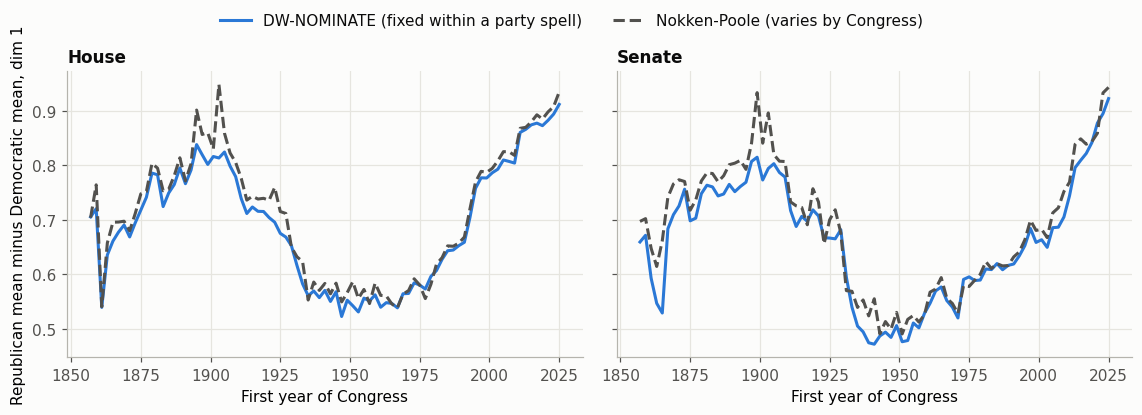

In [3]:
people = all_members.dropna(subset=["bioguide_id", "nominate_dim1"])
by_id = people.groupby("icpsr")["nominate_dim1"].nunique()
by_person = people.groupby("bioguide_id")["nominate_dim1"].nunique()
parties_per_person = people.groupby("bioguide_id")["icpsr"].nunique()
print(f"IDs whose dim 1 score ever changes: {(by_id > 1).sum()} of {len(by_id):,}")
print(f"People with more than one ID: {(parties_per_person > 1).sum()} of {len(parties_per_person):,}")
print(f"People whose dim 1 score changes: {(by_person > 1).sum()}")
examples = people[people["bioguide_id"].isin(by_person[by_person > 1].index)].drop_duplicates(["bioguide_id", "icpsr"])
display(examples[examples["bioname"].str.contains("THURMOND|SPECTER|SHELBY")][["bioname", "icpsr", "party", "nominate_dim1"]].sort_values("bioname"))

published = pd.read_csv(Path.cwd().parents[1] / "data_loading" / "data" / "raw" / "HSall_parties.csv")
published = published[published["party_code"].isin([100, 200])].pivot(index=["congress", "chamber"], columns="party_code", values="nominate_dim1_mean")
published = (published[200] - published[100]).rename("published_gap").reset_index()
compare = series.merge(published, on=["congress", "chamber"])
compare["difference"] = compare["dw_gap"] - compare["published_gap"]
print("Largest difference from Voteview's gap with delegates excluded:", round(compare["difference"].abs().max(), 4))
display(compare[compare["congress"].isin([116, 118, 119])][["congress", "chamber", "dw_gap", "published_gap", "difference"]].round(4))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True)
for axis, chamber in zip(axes, CHAMBERS):
    data = series[series["chamber"] == chamber]
    axis.plot(data["year"], data["dw_gap"], color=COLORS["D"], label="DW-NOMINATE (fixed within a party spell)")
    axis.plot(data["year"], data["np_gap"], color=NEUTRAL, linestyle="--", label="Nokken-Poole (varies by Congress)")
    axis.set_title(chamber)
    axis.set_xlabel("First year of Congress")
axes[0].set_ylabel("Republican mean minus Democratic mean, dim 1")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()


**What this shows**

- With delegates included, `validate.py` rebuilds all 727 published party means. That confirms the keys and filters, not the validity of the gap, because it averages Voteview's own scores.
- The series here excludes delegates, which raises the House gap by up to 0.002 in the Congresses shown. Quote these figures as delegate-excluded, not as Voteview's published values.
- A member's DW-NOMINATE score is fixed within a party spell. Voteview gives party switchers a new ID and score: 41 of 12,399 people have more than one ID, for example Specter (0.068 to -0.321).
- So this DW-NOMINATE series moves only through turnover and party switches. **It can't show sitting members converging.** Nokken-Poole can vary, but it comes from the same model, so it isn't an independent check.

## The same question from raw votes

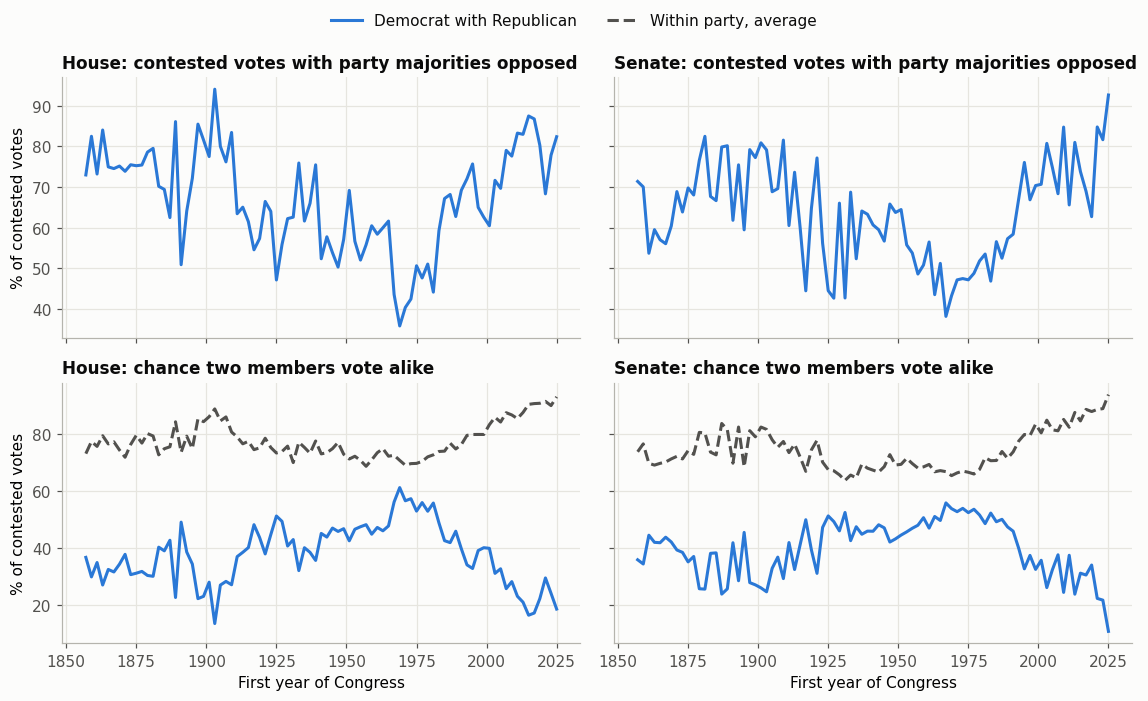

party_opposed        cross_agreement        dw_overlap         \
chamber          House Senate           House Senate      House Senate   
congress                                                                 
112              0.833  0.656           0.231  0.375        0.0    0.0   
113              0.830  0.810           0.210  0.238        0.0    0.0   
114              0.875  0.738           0.164  0.312        0.0    0.0   
115              0.867  0.690           0.172  0.305        0.0    0.0   
116              0.803  0.627           0.223  0.341        0.0    0.0   
117              0.683  0.848           0.295  0.223        0.0    0.0   
118              0.778  0.816           0.241  0.217        0.0    0.0   
119              0.824  0.926           0.186  0.107        0.0    0.0   

         np_overlap         
chamber       House Senate  
congress                    
112             0.0   0.00  
113             0.0   0.00  
114             0.0   0.00  
115             0.0   0.00  
116             0.0   0.00  
117             0.0   0.02  
118             0.0   0.00  
119             0.0   0.00

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 6.4), sharex=True, sharey="row")
for column, chamber in enumerate(CHAMBERS):
    data = series[series["chamber"] == chamber]
    axes[0, column].plot(data["year"], data["party_opposed"] * 100, color=COLORS["D"])
    axes[0, column].set_title(f"{chamber}: contested votes with party majorities opposed")
    axes[1, column].plot(data["year"], data["cross_agreement"] * 100, color=COLORS["D"], label="Democrat with Republican")
    within = (data["dem_agreement"] + data["rep_agreement"]) / 2 * 100
    axes[1, column].plot(data["year"], within, color=NEUTRAL, linestyle="--", label="Within party, average")
    axes[1, column].set_title(f"{chamber}: chance two members vote alike")
    axes[1, column].set_xlabel("First year of Congress")
axes[0, 0].set_ylabel("% of contested votes")
axes[1, 0].set_ylabel("% of contested votes")
handles, labels = axes[1, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

recent = series[series["congress"] >= 112].pivot(index="congress", columns="chamber", values=["party_opposed", "cross_agreement", "dw_overlap", "np_overlap"])
display(recent.round(3))


**What this shows**

- These measures come directly from votes, without NOMINATE scores. They use the same roll calls that NOMINATE was fitted on, so agreement with it is internal consistency, not outside validation.
- The broad U-shape is visible in both the score gap and the votes.
- The two lines in the lower panels aren't separate evidence. On each roll call, within-party minus cross-party agreement is close to the squared gap between the parties' Yea shares. Within-party agreement has risen since the 1960s, but it was also high around 1900.
- Single recent Congresses swing a lot. From the 114th to the 117th, House opposition fell from 87.5% to 68.3% while the Senate's rose from 73.8% to 84.8%. That may reflect the mix of votes, so recent claims below use the 2015 to 2023 average.
- The Senate's 10.7% cross-party agreement in the 119th is incomplete and isn't treated as a record.

## When were the parties closest?

In [5]:
def lowest_point(frame, measure, largest=False):
    row = frame.loc[frame[measure].idxmax() if largest else frame[measure].idxmin()]
    return row["year"], row[measure]


modern_era = complete[complete["year"] >= 1900]
rows = []
for chamber, frame in modern_era.groupby("chamber"):
    for measure, largest in [("dw_gap", False), ("np_gap", False), ("rice_gap", False), ("party_opposed", False), ("cross_agreement", True)]:
        year, value = lowest_point(frame, measure, largest)
        at = frame.set_index("year")[measure]
        rows.append({
            "chamber": chamber, "measure": measure, "closest_year": year, "value": value,
            "value_1947": at[1947], "value_1967": at[1967], "value_1969": at[1969],
        })
display(pd.DataFrame(rows).set_index(["chamber", "measure"]).round(3))

smoothed = modern_era.sort_values("year").groupby("chamber")[["dw_gap", "np_gap", "rice_gap", "party_opposed", "cross_agreement"]].rolling(3, center=True).mean().droplevel(0)
smoothed = modern_era[["chamber", "year"]].join(smoothed).dropna()
rows = []
for chamber, frame in smoothed.groupby("chamber"):
    row = {"chamber": chamber}
    for measure, largest in [("dw_gap", False), ("np_gap", False), ("rice_gap", False), ("party_opposed", False), ("cross_agreement", True)]:
        row[measure] = lowest_point(frame, measure, largest)[0]
    rows.append(row)
print("Closest year on a three-Congress average")
display(pd.DataFrame(rows).set_index("chamber"))

BOOTSTRAPS = 1000


def bootstrap_score_trough(chamber, column):
    frames = []
    for congress, group in members[(members["chamber"] == chamber) & members["party"].isin(["D", "R"])].dropna(subset=[column]).groupby("congress"):
        if first_year(congress) >= 1900 and congress < INCOMPLETE_CONGRESS:
            frames.append((first_year(congress), group.loc[group["party"] == "D", column].to_numpy(), group.loc[group["party"] == "R", column].to_numpy()))
    years = np.array([f[0] for f in frames])
    picks = []
    for _ in range(BOOTSTRAPS):
        gaps = [rng.choice(r, len(r)).mean() - rng.choice(d, len(d)).mean() for _, d, r in frames]
        picks.append(years[int(np.argmin(gaps))])
    return np.array(picks)


def bootstrap_vote_peak(chamber):
    frames = []
    for (congress, room), frame in contested_shares.groupby(["congress", "chamber"]):
        if room == chamber and first_year(congress) >= 1900 and congress < INCOMPLETE_CONGRESS:
            frames.append((first_year(congress), cross_agreement(frame).to_numpy()))
    years = np.array([f[0] for f in frames])
    picks = []
    for _ in range(BOOTSTRAPS):
        means = [rng.choice(values, len(values)).mean() for _, values in frames]
        picks.append(years[int(np.argmax(means))])
    return np.array(picks)


rows = []
for chamber in CHAMBERS:
    for name, picks in [
        ("dw_gap", bootstrap_score_trough(chamber, "nominate_dim1")),
        ("np_gap", bootstrap_score_trough(chamber, "nokken_poole_dim1")),
        ("cross_agreement", bootstrap_vote_peak(chamber)),
    ]:
        rows.append({
            "chamber": chamber, "measure": name, "low_2.5": np.quantile(picks, 0.025), "high_97.5": np.quantile(picks, 0.975),
            "most_common_year": pd.Series(picks).mode()[0], "share_at_mode": (picks == pd.Series(picks).mode()[0]).mean(),
            "share_before_1955": (picks < 1955).mean(),
        })
print("Bootstrap of the closest year, resampling members or roll calls within each Congress")
display(pd.DataFrame(rows).set_index(["chamber", "measure"]).round(3))

rows = []
for threshold in [0.0, 0.025, 0.10]:
    kept = shares[shares["minority_share"] >= threshold] if threshold else shares
    opposed = ((kept["D"] - 0.5) * (kept["R"] - 0.5) < 0).groupby(["congress", "chamber"]).mean().rename("party_opposed")
    agreement = cross_agreement(kept).groupby(["congress", "chamber"]).mean().rename("cross_agreement")
    frame = pd.concat([opposed, agreement], axis=1).reset_index().merge(complete[["congress", "chamber", "year", "dw_gap"]], on=["congress", "chamber"])
    for chamber, part in frame.groupby("chamber"):
        era = part[part["year"] >= 1900]
        rows.append({
            "cutoff": threshold, "chamber": chamber,
            "peak_agreement_year": lowest_point(era, "cross_agreement", True)[0],
            "peak_agreement": lowest_point(era, "cross_agreement", True)[1],
            "lowest_opposed_year": lowest_point(era, "party_opposed")[0],
            "opposed_vs_dw_gap": part["party_opposed"].corr(part["dw_gap"]),
            "agreement_vs_dw_gap": part["cross_agreement"].corr(part["dw_gap"]),
            "opposed_2023": part.set_index("year").loc[2023, "party_opposed"],
        })
print("Sensitivity to the near-unanimous cutoff, complete Congresses, by chamber")
display(pd.DataFrame(rows).set_index(["chamber", "cutoff"]).sort_index().round(3))


closest_year  value  value_1947  value_1967  \
chamber measure                                                        
House   dw_gap                   1947  0.523       0.523       0.539   
        np_gap                   1967  0.539       0.549       0.539   
        rice_gap                 1969  0.241       0.473       0.316   
        party_opposed            1969  0.359       0.503       0.436   
        cross_agreement          1969  0.613       0.459       0.562   
Senate  dw_gap                   1941  0.472       0.484       0.552   
        np_gap                   1951  0.491       0.499       0.556   
        rice_gap                 1967  0.264       0.486       0.264   
        party_opposed            1967  0.382       0.658       0.382   
        cross_agreement          1967  0.559       0.422       0.559   

                         value_1969  
chamber measure                      
House   dw_gap                0.564  
        np_gap                0.564  
        rice_gap              0.241  
        party_opposed         0.359  
        cross_agreement       0.613  
Senate  dw_gap                0.540  
        np_gap                0.547  
        rice_gap              0.279  
        party_opposed         0.433  
        cross_agreement       0.539

Closest year on a three-Congress average


,dw_gap,np_gap,rice_gap,party_opposed,cross_agreement
chamber,,,,,
House,1949,1965,1971,1971,1971
Senate,1941,1945,1969,1969,1969


Bootstrap of the closest year, resampling members or roll calls within each Congress


low_2.5  high_97.5  most_common_year  share_at_mode  \
chamber measure                                                                
House   dw_gap            1943.0    1967.00              1947          0.382   
        np_gap            1935.0    1977.00              1967          0.259   
        cross_agreement   1969.0    1969.00              1969          1.000   
Senate  dw_gap            1937.0    1959.05              1951          0.148   
        np_gap            1937.0    1971.00              1943          0.168   
        cross_agreement   1967.0    1971.00              1967          0.941   

                         share_before_1955  
chamber measure                             
House   dw_gap                       0.719  
        np_gap                       0.339  
        cross_agreement              0.000  
Senate  dw_gap                       0.894  
        np_gap                       0.724  
        cross_agreement              0.003

Sensitivity to the near-unanimous cutoff, complete Congresses, by chamber


peak_agreement_year  peak_agreement  lowest_opposed_year  \
chamber cutoff                                                             
House   0.000                  1969           0.688                 1969   
        0.025                  1969           0.613                 1969   
        0.100                  1969           0.531                 1969   
Senate  0.000                  1967           0.615                 1967   
        0.025                  1967           0.559                 1967   
        0.100                  1931           0.509                 1927   

                opposed_vs_dw_gap  agreement_vs_dw_gap  opposed_2023  
chamber cutoff                                                        
House   0.000               0.487               -0.563         0.705  
        0.025               0.656               -0.748         0.778  
        0.100               0.710               -0.798         0.864  
Senate  0.000               0.600               -0.688         0.779  
        0.025               0.615               -0.726         0.816  
        0.100               0.618               -0.733         0.854

**What this shows**

- **The score gap has a broad mid-century trough, not a clear lowest year.** The closest year varies by measure and the differences are small: House DW-NOMINATE is 0.523 in 1947 and 0.539 in 1967, while House Nokken-Poole reverses that order (0.549 and 0.539). Bootstrap ranges are wide: 1943 to 1967 for House DW-NOMINATE, and 1935 to 1977 for Nokken-Poole.
- **Votes point more sharply to the late 1960s at the default cutoff.** Cross-party agreement peaks in 1969 in the House (61.3%, bootstrap range 1969 only) and 1967 in the Senate (55.9%, range 1967 to 1971).
- **The House peak is stable across cutoffs; the Senate's isn't.** The House stays at 1969 at all three cutoffs. The Senate stays at 1967 at 0% and 2.5%, then moves to 1931 at 10%, and its lowest opposition moves to 1927.
- The bootstrap covers sampling noise only, not changes in the agenda.
- So the safe statement is a mid-century trough whose lowest point varies by measure. Votes place it in the late 1960s in the House. In the Senate, that depends on how many near-unanimous votes are kept. Why votes and scores differ remains unexplained; the second dimension, fixed career scores and the agenda are all candidates.

The cutoff also changes levels: the 118th House figure runs from 70.5% to 86.4%, so percentages should always be quoted with their cutoff.

## Is the recent period beyond the earlier peak?

In [6]:
rows = []
for chamber, frame in complete.groupby("chamber"):
    early = frame[frame["year"] < 1945]
    recent_years = frame[frame["congress"].between(114, 118)]
    for measure, separated_high in [("dw_gap", True), ("np_gap", True), ("rice_gap", True), ("party_opposed", True), ("cross_agreement", False)]:
        year, extreme = lowest_point(early, measure, separated_high)
        recent_mean = recent_years[measure].mean()
        rows.append({
            "chamber": chamber, "measure": measure, "earlier_extreme": extreme, "earlier_year": year,
            "mean_2015_2023": recent_mean, "value_2023": frame.set_index("year").loc[2023, measure],
            "recent_mean_beyond_earlier": recent_mean > extreme if separated_high else recent_mean < extreme,
        })
display(pd.DataFrame(rows).set_index(["chamber", "measure"]).round(3))

rows = []
for chamber, frame in complete.groupby("chamber"):
    row = frame.loc[frame["np_overlap"].idxmax()]
    dw_row = frame.loc[frame["dw_overlap"].idxmax()]
    rows.append({
        "chamber": chamber, "peak_np_overlap": row["np_overlap"], "np_year": row["year"],
        "peak_dw_overlap": dw_row["dw_overlap"], "dw_year": dw_row["year"],
        "last_year_np_overlap": frame.loc[frame["np_overlap"] > 0, "year"].max(),
        "last_year_dw_overlap": frame.loc[frame["dw_overlap"] > 0, "year"].max(),
    })
display(pd.DataFrame(rows).set_index("chamber").round(3))


earlier_extreme  earlier_year  mean_2015_2023  \
chamber measure                                                          
House   dw_gap                     0.838          1895           0.880   
        np_gap                     0.949          1903           0.893   
        rice_gap                   0.822          1903           0.768   
        party_opposed              0.940          1903           0.801   
        cross_agreement            0.135          1903           0.219   
Senate  dw_gap                     0.815          1899           0.849   
        np_gap                     0.933          1899           0.865   
        rice_gap                   0.711          1887           0.708   
        party_opposed              0.825          1881           0.744   
        cross_agreement            0.238          1887           0.280   

                         value_2023  recent_mean_beyond_earlier  
chamber measure                                                  
House   dw_gap                0.894                        True  
        np_gap                0.908                       False  
        rice_gap              0.748                       False  
        party_opposed         0.778                       False  
        cross_agreement       0.241                       False  
Senate  dw_gap                0.895                        True  
        np_gap                0.933                       False  
        rice_gap              0.771                       False  
        party_opposed         0.816                       False  
        cross_agreement       0.217                       False

,peak_np_overlap,np_year,peak_dw_overlap,dw_year,last_year_np_overlap,last_year_dw_overlap
chamber,,,,,,
House,0.704,1943,0.641,1935,2001,2001
Senate,0.559,1931,0.429,1947,2021,2003


**What this shows**

- **Only the DW-NOMINATE gap has passed its earlier peak.** Its 2015 to 2023 average is 0.880 in the House and 0.849 in the Senate, against pre-1945 highs of 0.838 and 0.815.
- **Nokken-Poole and the raw-vote measures have not**, on that average. House party opposition averages 80.1%, against 94.0% in 1903. House cross-party agreement averages 21.9%, against a low of 13.5% in 1903. The Senate's Rice gap is the nearest, 0.708 against 0.711.
- Taken on 2023 alone, the Senate's Nokken-Poole gap and cross-party agreement are close to or past their earlier extremes, so the unfinished 119th may change this.
- "The most polarized era ever" therefore holds on DW-NOMINATE but not on every measure. Comparing eras also assumes a stable agenda and scale.

**Overlap:** no member has sat between the parties on DW-NOMINATE since the Congress beginning in 2003 in the Senate and 2001 in the House. Peak overlap was 64% in the House (1935) and 43% in the Senate (1947). Nokken-Poole peaks are higher, 70% and 56%, but are noisier because they depend on the most extreme members. The Senate's 2021 overlap on that measure is about two members.

## Do raw-vote measures agree with DW-NOMINATE?

All complete Congresses with two main parties


n  levels_pearson  levels_spearman  changes_pearson  \
chamber measure                                                                 
House   party_opposed    84           0.656            0.667            0.270   
        rice_gap         84           0.784            0.766            0.264   
        cross_agreement  84          -0.748           -0.740           -0.277   
Senate  party_opposed    84           0.615            0.634            0.199   
        rice_gap         84           0.730            0.729            0.202   
        cross_agreement  84          -0.726           -0.722           -0.179   

                         changes_low  changes_high  
chamber measure                                     
House   party_opposed          0.094         0.411  
        rice_gap               0.061         0.429  
        cross_agreement       -0.426        -0.112  
Senate  party_opposed         -0.054         0.458  
        rice_gap              -0.012         0.410  
        cross_agreement       -0.396         0.040

From Congress 79 (1945)


n  levels_pearson  levels_spearman  changes_pearson  \
chamber measure                                                                 
House   party_opposed    40           0.803            0.759            0.202   
        rice_gap         40           0.904            0.791            0.075   
        cross_agreement  40          -0.888           -0.780           -0.193   
Senate  party_opposed    40           0.668            0.670            0.042   
        rice_gap         40           0.799            0.720           -0.002   
        cross_agreement  40          -0.772           -0.670           -0.012   

                         changes_low  changes_high  
chamber measure                                     
House   party_opposed         -0.041         0.410  
        rice_gap              -0.173         0.324  
        cross_agreement       -0.430         0.070  
Senate  party_opposed         -0.322         0.365  
        rice_gap              -0.400         0.352  
        cross_agreement       -0.378         0.391

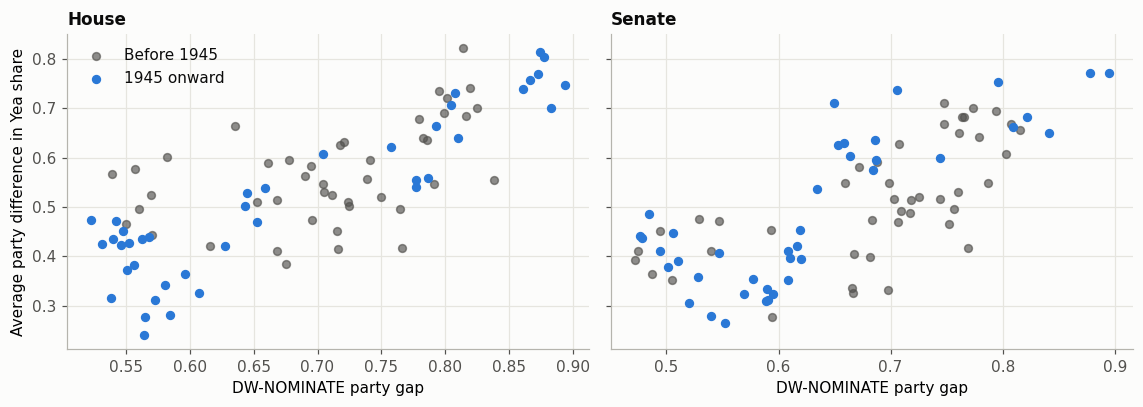

In [7]:
MEASURE_NAMES = ["party_opposed", "rice_gap", "cross_agreement"]


def bootstrap_interval(frame, a, b):
    values = frame[[a, b]].to_numpy()
    results = []
    for _ in range(2000):
        sample = values[rng.integers(0, len(values), len(values))]
        results.append(np.corrcoef(sample[:, 0], sample[:, 1])[0, 1])
    return np.quantile(results, [0.025, 0.975])


def agreement_table(data):
    rows = []
    for chamber, frame in data.groupby("chamber"):
        frame = frame.sort_values("congress")
        for measure in MEASURE_NAMES:
            changes = frame[["dw_gap", measure]].diff().dropna()
            low, high = bootstrap_interval(changes, "dw_gap", measure)
            rows.append({
                "chamber": chamber, "measure": measure, "n": len(frame),
                "levels_pearson": frame["dw_gap"].corr(frame[measure]),
                "levels_spearman": frame["dw_gap"].corr(frame[measure], method="spearman"),
                "changes_pearson": changes["dw_gap"].corr(changes[measure]),
                "changes_low": low, "changes_high": high,
            })
    return pd.DataFrame(rows).set_index(["chamber", "measure"]).round(3)


print("All complete Congresses with two main parties")
display(agreement_table(complete))
print(f"From Congress {MODERN_CONGRESS} (1945)")
display(agreement_table(complete[complete["congress"] >= MODERN_CONGRESS]))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True)
for axis, chamber in zip(axes, CHAMBERS):
    data = complete[complete["chamber"] == chamber]
    modern = data["congress"] >= MODERN_CONGRESS
    axis.scatter(data.loc[~modern, "dw_gap"], data.loc[~modern, "rice_gap"], s=26, color=NEUTRAL, alpha=0.65, label="Before 1945")
    axis.scatter(data.loc[modern, "dw_gap"], data.loc[modern, "rice_gap"], s=26, color=COLORS["D"], label="1945 onward")
    axis.set_title(chamber)
    axis.set_xlabel("DW-NOMINATE party gap")
axes[0].set_ylabel("Average party difference in Yea share")
axes[0].legend()
fig.tight_layout()
plt.show()


**What this shows**

These compare raw-vote measures with the DW-NOMINATE gap. PC1 is left out because it isn't on a common scale across eras.

- **Levels agree moderately to strongly.** Absolute Pearson correlations run from 0.62 to 0.78 over the full period and 0.67 to 0.90 since 1945. Spearman runs from 0.63 to 0.77 and 0.67 to 0.79. Shared long-run trends inflate these, so the effective sample is smaller than 84 or 40.
- **Changes between Congresses show a weak or undetectable link.** Absolute correlations are at most 0.28. Since 1945 every bootstrap interval includes zero, and intervals are wide, so this means not detected, not no relationship.
- A weak link in changes doesn't show which series is at fault. Fixed scores can't follow within-person change, and raw votes respond to the agenda. Whether the DW-NOMINATE gap tracks short-run change is unresolved.

## Is recent voting one-dimensional?

In [8]:
pc_columns = ["pc1_variance_share", "pc2_variance_share", "pc1_dw_corr"]
display(series[series["congress"].isin([60, 80, 90, 95, 100, 105, 110, 115, 118])].set_index(["chamber", "congress"]).sort_index()[pc_columns].round(3))
print("Congresses where PC1 correlates below 0.8 with DW-NOMINATE dim 1:")
print(complete[complete["pc1_dw_corr"].abs() < 0.8].groupby("chamber").size().to_dict())


pc1_variance_share  pc2_variance_share  pc1_dw_corr
chamber congress                                                     
House   60                     0.278               0.034        0.933
        80                     0.415               0.081        0.894
        90                     0.363               0.084        0.906
        95                     0.305               0.050        0.927
        100                    0.455               0.043        0.972
        105                    0.507               0.032        0.967
        110                    0.693               0.034        0.961
        115                    0.757               0.030        0.952
        118                    0.712               0.060        0.965
Senate  60                     0.350               0.080        0.928
        80                     0.408               0.074        0.910
        90                     0.261               0.094        0.832
        95                     0.307               0.044        0.871
        100                    0.339               0.062        0.965
        105                    0.529               0.036        0.985
        110                    0.563               0.043        0.975
        115                    0.669               0.049        0.947
        118                    0.671               0.053        0.949

Congresses where PC1 correlates below 0.8 with DW-NOMINATE dim 1:
{'Senate': 8}


**What this shows**

- PC1's share of variance is higher in recent Congresses than in the 1970s: 30.5% in 1977 to 71.2% in 2023 in the House, and 30.7% to 67.1% in the Senate. PC2 is about 3% to 6% in those recent Congresses.
- This is descriptive. It depends on the agenda and on mean-imputed absences, and components fitted separately aren't aligned between Congresses.
- PC1 tracks DW-NOMINATE closely in most Congresses, but 8 Senate Congresses fall below 0.8, so PC1 isn't always the same axis.
- Even so, a single main axis in recent Congresses suggests that two-cluster results there will largely reproduce party. Step 2 needs to test that.

## Members who stayed, first look

In [9]:
def within_person_change(start, end, chamber):
    frame = members[(members["chamber"] == chamber) & members["party"].isin(["D", "R"])].dropna(subset=["bioguide_id"])
    before = frame[frame["congress"] == start].drop_duplicates("bioguide_id", keep="last").set_index("bioguide_id")
    after = frame[frame["congress"] == end].drop_duplicates("bioguide_id", keep="first").set_index("bioguide_id")
    stayers = before.index.intersection(after.index)
    same_party = stayers[before.loc[stayers, "party"] == after.loc[stayers, "party"]]
    change = after.loc[same_party, "nokken_poole_dim1"] - before.loc[same_party, "nokken_poole_dim1"]
    party = before.loc[same_party, "party"]
    gaps = series[series["chamber"] == chamber].set_index("congress")
    return {
        "chamber": chamber, "period": f"{first_year(start)} to {first_year(end)}",
        "stayers_D": (party == "D").sum(), "stayers_R": (party == "R").sum(),
        "party_switchers": len(stayers) - len(same_party),
        "mean_change_D": change[party == "D"].mean(), "mean_change_R": change[party == "R"].mean(),
        "stayer_gap_change": change[party == "R"].mean() - change[party == "D"].mean(),
        "np_gap_change": gaps.loc[end, "np_gap"] - gaps.loc[start, "np_gap"],
    }


windows = [(100, 105), (105, 110), (110, 115)]
display(pd.DataFrame([within_person_change(a, b, c) for c in CHAMBERS for a, b in windows]).set_index(["chamber", "period"]).round(3))


stayers_D  stayers_R  party_switchers  mean_change_D  \
chamber period                                                               
House   1987 to 1997         80         67                2          0.006   
        1997 to 2007        126        101                2         -0.017   
        2007 to 2017         98         72                0         -0.006   
Senate  1987 to 1997         25         19                1          0.011   
        1997 to 2007         29         29                0         -0.022   
        2007 to 2017         19         23                0          0.018   

                      mean_change_R  stayer_gap_change  np_gap_change  
chamber period                                                         
House   1987 to 1997          0.006             -0.001          0.137  
        1997 to 2007          0.001              0.018          0.036  
        2007 to 2017         -0.007             -0.001          0.068  
Senate  1987 to 1997         -0.001             -0.012          0.084  
        1997 to 2007          0.005              0.028          0.023  
        2007 to 2017         -0.006             -0.024          0.117

**What this shows**

People are linked by Bioguide ID, so party switchers are tracked correctly and counted separately. There are only 5 across these windows.

- Among stayers, the implied gap change is small in most windows, for example -0.001 in the House from 1987 to 1997 while the Nokken-Poole gap grew by 0.137.
- From 1997 to 2007, stayers' change is larger relative to the overall change: 0.018 of 0.036 in the House, and 0.028 against 0.023 in the Senate. So the pattern isn't uniform.

This suggests turnover often matters, but it is **not a decomposition**. Long-serving members are a selected group, Nokken-Poole depends on fixed DW-NOMINATE cutting lines that may limit movement, and Senate groups are small. Step 2 needs a proper replacement versus conversion analysis.

## Summary

**Supported**

- Separation was high around 1900, lower in a broad mid-century trough, and has been rising since the 1970s, on both scores and raw votes.
- The DW-NOMINATE gap in 2023 was the widest of any completed Congress: 0.894 in the House and 0.895 in the Senate, delegates excluded.
- No member has sat between the parties on DW-NOMINATE since the early 2000s.

**Depends on the measure**

- Only DW-NOMINATE has passed its earlier peak. Nokken-Poole and raw-vote averages for 2015 to 2023 have not.
- Votes place peak cross-party agreement in 1969 in the House. The Senate's 1967 peak moves to 1931 under a stricter cutoff.

**Unresolved**

- How much recent separation comes from turnover or from sitting members changing.
- Whether DW-NOMINATE tracks short-run change.
- How much the agenda contributes to any of these results.

**For step 2:** link people by Bioguide ID, keep testing cutoffs, compare periods using multi-Congress averages, and focus on periods, issues, factions and turnover instead of two-cluster splits of recent Congresses.